<a href="https://colab.research.google.com/github/akashkumarcs24-cloud/BIS_LAB/blob/main/CuckooSearch.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
#!/usr/bin/env python3
"""
MRI brain tumor segmentation with Cuckoo-search dimensionality reduction and an
Ensemble of CNNs (ECNN) -- a runnable implementation of the pipeline described in
Shenbagarajan et al., Open Biomed. Eng. J. 2024, 18, e18741207290221.

Pipeline (paper Fig. 1)
    slice -> pre-processing (bias-field correction + intensity normalisation)
          -> patch extraction -> Cuckoo-search dimensionality reduction
          -> ensemble of 4 CNNs (equal / accuracy-weighted / rank-weighted averaging)
          -> post-processing (remove clusters smaller than T_VOL)
          -> DSC / PPV / Sensitivity vs. a single CNN and a Random Forest

Dependencies: numpy, scipy, scikit-learn, matplotlib   (no deep-learning framework)

NOTE: BRATS cannot be downloaded offline, so by default the script generates
synthetic 2-D "MRI" slices (bias field, Rician noise, HGG = strong ring-enhancing
lesion, LGG = faint lesion). To use real data, replace `make_dataset()` so it
returns a list of dicts with keys: img, gt (bool), brain (bool), grade ("HGG"/"LGG").

Usage in Colab: run this cell, then run  main()  (or  main(["--quick"])  for a fast test).
"""
import argparse
import csv
import os
import time
from math import gamma, pi, sin

import matplotlib.pyplot as plt
import numpy as np
from numpy.lib.stride_tricks import sliding_window_view
from scipy import ndimage as ndi
from scipy.interpolate import interp1d
from sklearn.ensemble import RandomForestClassifier

PATCH = 11          # patch size -> 121 candidate features for the cuckoo search
PAD = PATCH // 2
T_VOL = 10          # post-processing: drop connected clusters smaller than this (pixels)
COLORS = {"Random Forest": "#3b6fb6", "CNN": "#d1495b", "CNN + CS": "#edae49", "ECNN": "#66a61e"}


# ----------------------------------------------------------------------------
# 1. Synthetic data (stand-in for BRATS)
# ----------------------------------------------------------------------------
def synth_slice(rng, grade, size=64):
    yy, xx = np.mgrid[0:size, 0:size].astype(float)
    cx, cy = size / 2 + rng.normal(0, 1.5), size / 2 + rng.normal(0, 1.5)
    a, b = size * rng.uniform(0.38, 0.43), size * rng.uniform(0.43, 0.47)
    d = ((xx - cx) / a) ** 2 + ((yy - cy) / b) ** 2
    brain = d < 1

    img = np.zeros((size, size))
    img[brain] = 0.62                                   # white matter
    img[brain & (d > 0.62)] = 0.45                      # grey-matter rim
    for s in (-1, 1):                                   # CSF ventricles
        v = ((xx - cx - s * 0.09 * size) / (0.05 * size)) ** 2 + ((yy - cy) / (0.12 * size)) ** 2 < 1
        img[v & brain] = 0.15
    tex = ndi.gaussian_filter(rng.normal(size=img.shape), 1.2)
    img += brain * 0.03 * tex / tex.std()

    # tumour: irregular blob somewhere in the brain
    rr, th = rng.uniform(0, 0.5), rng.uniform(0, 2 * pi)
    tx, ty = cx + rr * a * np.cos(th), cy + rr * b * np.sin(th)
    r = rng.uniform(6, 10) if grade == "HGG" else rng.uniform(5, 9)
    n = ndi.gaussian_filter(rng.normal(size=img.shape), 3)
    field = np.hypot(xx - tx, yy - ty) / r + 0.35 * n / n.std()
    tumor = (field < 1) & brain
    if grade == "HGG":
        img[tumor] += 0.30                              # enhancing rim
        img[(field < 0.45) & brain] -= 0.12             # necrotic core
    else:
        img[tumor] += 0.11                              # faint, low contrast

    # acquisition artefacts: multiplicative bias field + Rician noise
    bias = ndi.gaussian_filter(rng.normal(size=img.shape), 12)
    img = img * (1 + 0.25 * bias / bias.std() * 0.6)
    img = np.sqrt((img + rng.normal(0, 0.025, img.shape)) ** 2 + rng.normal(0, 0.025, img.shape) ** 2)
    return img.astype(np.float32), tumor, brain


def make_dataset(rng, n_per_grade, size=64):
    data = []
    for g in ("HGG", "LGG"):
        for _ in range(n_per_grade):
            img, gt, brain = synth_slice(rng, g, size)
            data.append(dict(img=img, gt=gt, brain=brain, grade=g))
    rng.shuffle(data)
    return data


# ----------------------------------------------------------------------------
# 2. Pre-processing: bias correction (N4ITK stand-in) + landmark normalisation
# ----------------------------------------------------------------------------
def bias_correct(img, brain, sigma=8):
    est = ndi.gaussian_filter(img * brain, sigma) / (ndi.gaussian_filter(brain.astype(float), sigma) + 1e-6)
    est = np.where(brain, est, 1.0)
    return np.where(brain, img / (est + 1e-6) * est[brain].mean(), 0.0), est


class IntensityNormalizer:
    """Nyul-style piece-wise linear landmark matching followed by z-scoring."""
    PCT = [5, 25, 50, 75]

    def fit(self, slices):
        lms = [np.percentile(s["bc"][s["brain"]], self.PCT) for s in slices]
        self.std_lm = np.mean(lms, axis=0)
        mapped = np.concatenate([self._map(s["bc"], s["brain"])[s["brain"]] for s in slices])
        self.mu, self.sd = mapped.mean(), mapped.std()
        return self

    def _map(self, img, brain):
        lm = np.percentile(img[brain], self.PCT)
        f = interp1d(lm, self.std_lm, kind="linear", fill_value="extrapolate")
        return f(img)

    def __call__(self, img, brain):
        return np.where(brain, (self._map(img, brain) - self.mu) / self.sd, 0.0).astype(np.float32)


def preprocess(data, normalizer=None):
    for s in data:
        s["bc"], s["bias_est"] = bias_correct(s["img"], s["brain"])
    if normalizer is None:
        normalizer = IntensityNormalizer().fit(data)
    for s in data:
        s["norm"] = normalizer(s["bc"], s["brain"])
    return normalizer


# ----------------------------------------------------------------------------
# 3. Patch extraction
# ----------------------------------------------------------------------------
def patches_at(img, sel):
    win = sliding_window_view(np.pad(img, PAD, mode="reflect"), (PATCH, PATCH))
    return win[sel].astype(np.float32)


def sample_training_patches(data, rng, n_tumor=100, n_bg=300):
    """Tumour pixels + background (half random, half 'hard' ones near the lesion)."""
    X, y = [], []
    for s in data:
        gt, brain = s["gt"], s["brain"]
        near = ndi.binary_dilation(gt, iterations=6) & brain & ~gt
        far = brain & ~gt & ~near
        for mask, n, lab in ((gt, n_tumor, 1), (near, n_bg // 2, 0), (far, n_bg // 2, 0)):
            idx = np.argwhere(mask)
            if len(idx) == 0:
                continue
            idx = idx[rng.choice(len(idx), min(n, len(idx)), replace=False)]
            sel = np.zeros_like(gt)
            sel[idx[:, 0], idx[:, 1]] = True
            p = patches_at(s["norm"], sel)
            X.append(p)
            y.append(np.full(len(p), lab))
    X, y = np.concatenate(X), np.concatenate(y)
    perm = rng.permutation(len(y))
    return X[perm], y[perm]


# ----------------------------------------------------------------------------
# 4. Cuckoo search for dimensionality reduction (paper section 3.3)
# ----------------------------------------------------------------------------
def levy(rng, size, beta=1.5):
    """Mantegna's algorithm; step lengths ~ t^-lambda with lambda = beta + 1."""
    sigma = (gamma(1 + beta) * sin(pi * beta / 2) / (gamma((1 + beta) / 2) * beta * 2 ** ((beta - 1) / 2))) ** (1 / beta)
    return rng.normal(0, sigma, size) / np.abs(rng.normal(0, 1, size)) ** (1 / beta)


class CuckooFeatureSelector:
    """
    Each nest is a vector in [0,1]^121; value > 0.5 keeps that patch position.
    Fitness g(x) = Dice similarity of a fast linear classifier on the kept
    positions (validation set) minus a small penalty for the number of kept
    positions (the best subset should have the fewest dimensions).
    """

    def __init__(self, Xtr, ytr, Xva, yva, rng, n_nests=15, max_gen=30, pa=0.25, alpha=0.15, penalty=0.03):
        self.Xtr, self.ytr = Xtr.reshape(len(Xtr), -1), ytr.astype(float)
        self.Xva, self.yva = Xva.reshape(len(Xva), -1), yva.astype(bool)
        self.rng, self.n, self.G, self.pa, self.alpha, self.pen = rng, n_nests, max_gen, pa, alpha, penalty
        self.dim = self.Xtr.shape[1]
        self.A_tr = np.hstack([self.Xtr, np.ones((len(self.Xtr), 1))])
        self.A_va = np.hstack([self.Xva, np.ones((len(self.Xva), 1))])

    def fitness(self, x):
        m = x > 0.5
        if not m.any():
            return 0.0
        cols = np.append(m, True)
        w, *_ = np.linalg.lstsq(self.A_tr[:, cols], self.ytr, rcond=None)
        pred = (self.A_va[:, cols] @ w) > 0.5
        tp = (pred & self.yva).sum()
        dice = 2 * tp / (pred.sum() + self.yva.sum() + 1e-9)
        return dice - self.pen * m.mean()

    def run(self):
        rng = self.rng
        X = rng.random((self.n, self.dim))                     # 1. initial population of nests
        F = np.array([self.fitness(x) for x in X])
        hist = dict(best=[], mean=[], n_sel=[])
        for _ in range(self.G):                                # 2. while t < MaxGeneration
            best = X[F.argmax()].copy()
            Xn = np.clip(X + self.alpha * levy(rng, X.shape), 0, 1)       # 2.1 Levy flights
            Fn = np.array([self.fitness(x) for x in Xn])                  # 2.2 fitness
            for i in range(self.n):                                       # 2.3-2.4 compare with random nest k
                k = rng.integers(self.n)
                if Fn[i] > F[k]:
                    X[k], F[k] = Xn[i], Fn[i]
            # 2.4.2 abandon a fraction pa of the worst nests, build new ones
            worst = np.argsort(F)[: int(self.pa * self.n)]
            for i in worst:
                a, b = rng.choice(self.n, 2, replace=False)
                cand = np.clip(X[i] + rng.random() * (X[a] - X[b]) * (rng.random(self.dim) < 0.5), 0, 1)
                fc = self.fitness(cand)
                if fc > F[i]:
                    X[i], F[i] = cand, fc
            if F.max() < self.fitness(best):                              # 2.4.3 keep the best nest
                X[F.argmin()], F[F.argmin()] = best, self.fitness(best)
            hist["best"].append(F.max())
            hist["mean"].append(F.mean())
            hist["n_sel"].append(int((X[F.argmax()] > 0.5).sum()))
        mask = (X[F.argmax()] > 0.5).reshape(PATCH, PATCH)
        return mask, hist


# ----------------------------------------------------------------------------
# 5. CNN in NumPy: conv3x3 -> ReLU -> maxpool2 -> dense -> ReLU -> dropout -> softmax
# ----------------------------------------------------------------------------
class NumpyCNN:
    def __init__(self, n_filters=8, hidden=32, lr=2e-3, dropout=0.3, l2=1e-4, seed=0, mask=None):
        self.F, self.H, self.lr, self.drop, self.l2 = n_filters, hidden, lr, dropout, l2
        self.rng = np.random.default_rng(seed)
        self.mask = None if mask is None else mask.astype(np.float32)
        self.co = PATCH - 2                  # conv output size
        self.po = self.co // 2               # pooled size
        flat = self.po * self.po * self.F
        r = self.rng
        self.p = dict(
            Wc=r.normal(0, np.sqrt(2 / 9), (9, self.F)), bc=np.zeros(self.F),
            W2=r.normal(0, np.sqrt(2 / flat), (flat, self.H)), b2=np.zeros(self.H),
            W3=r.normal(0, np.sqrt(2 / self.H), (self.H, 2)), b3=np.zeros(2),
        )
        self.m = {k: np.zeros_like(v) for k, v in self.p.items()}
        self.v = {k: np.zeros_like(v) for k, v in self.p.items()}
        self.t = 0

    # -- forward / backward -------------------------------------------------
    def _forward(self, X, train=False):
        if self.mask is not None:
            X = X * self.mask
        N, p = len(X), self.p
        cols = sliding_window_view(X, (3, 3), axis=(1, 2)).reshape(N, self.co ** 2, 9)
        z1 = cols @ p["Wc"] + p["bc"]
        a1 = np.maximum(z1, 0).reshape(N, self.co, self.co, self.F)
        c = a1[:, : 2 * self.po, : 2 * self.po].reshape(N, self.po, 2, self.po, 2, self.F)
        pooled = c.max(axis=(2, 4))
        flat = pooled.reshape(N, -1)
        z2 = flat @ p["W2"] + p["b2"]
        a2 = np.maximum(z2, 0)
        dm = None
        if train and self.drop > 0:
            dm = (self.rng.random(a2.shape) > self.drop) / (1 - self.drop)
            a2 = a2 * dm
        z3 = a2 @ p["W3"] + p["b3"]
        z3 -= z3.max(1, keepdims=True)
        e = np.exp(z3)
        probs = e / e.sum(1, keepdims=True)
        return probs, (cols, a1, c, pooled, flat, z2, a2, dm)

    def _backward(self, probs, y, cache):
        cols, a1, c, pooled, flat, z2, a2, dm = cache
        N, p = len(y), self.p
        dz3 = probs.copy()
        dz3[np.arange(N), y] -= 1
        dz3 /= N
        g = dict(W3=a2.T @ dz3, b3=dz3.sum(0))
        da2 = dz3 @ p["W3"].T
        if dm is not None:
            da2 = da2 * dm
        dz2 = da2 * (z2 > 0)
        g["W2"], g["b2"] = flat.T @ dz2, dz2.sum(0)
        dpool = (dz2 @ p["W2"].T).reshape(N, self.po, self.po, self.F)
        sel = (c == pooled[:, :, None, :, None, :])
        dc = sel * dpool[:, :, None, :, None, :]
        da1 = np.zeros_like(a1)
        da1[:, : 2 * self.po, : 2 * self.po] = dc.reshape(N, 2 * self.po, 2 * self.po, self.F)
        dz1 = (da1 * (a1 > 0)).reshape(N, self.co ** 2, self.F)
        g["Wc"], g["bc"] = np.einsum("npk,npf->kf", cols, dz1), dz1.sum((0, 1))
        for k in ("Wc", "W2", "W3"):
            g[k] = g[k] + self.l2 * p[k]
        return g

    def _adam(self, g, b1=0.9, b2=0.999, eps=1e-8):
        self.t += 1
        for k in self.p:
            self.m[k] = b1 * self.m[k] + (1 - b1) * g[k]
            self.v[k] = b2 * self.v[k] + (1 - b2) * g[k] ** 2
            mh, vh = self.m[k] / (1 - b1 ** self.t), self.v[k] / (1 - b2 ** self.t)
            self.p[k] -= self.lr * mh / (np.sqrt(vh) + eps)

    # -- public API -----------------------------------------------------------
    def fit(self, X, y, Xv, yv, epochs=12, batch=128):
        hist = dict(loss=[], val_acc=[])
        for _ in range(epochs):
            perm = self.rng.permutation(len(y))
            tot = 0.0
            for i in range(0, len(y), batch):
                b = perm[i:i + batch]
                probs, cache = self._forward(X[b], train=True)
                tot += -np.log(probs[np.arange(len(b)), y[b]] + 1e-9).sum()
                self._adam(self._backward(probs, y[b], cache))
            hist["loss"].append(tot / len(y))
            hist["val_acc"].append(float((self.predict_proba(Xv).argmax(1) == yv).mean()))
        return hist

    def predict_proba(self, X, batch=4096):
        out = [self._forward(X[i:i + batch])[0] for i in range(0, len(X), batch)]
        return np.concatenate(out) if out else np.zeros((0, 2))


# ----------------------------------------------------------------------------
# 6. Ensemble (paper section 3.5, Eqs. 3-6)
# ----------------------------------------------------------------------------
def ensemble_weights(val_acc, scheme):
    a = np.asarray(val_acc, float)
    if scheme == "equal":                                  # Eq. 3
        return np.full(len(a), 1 / len(a))
    if scheme == "accuracy":                               # Eq. 5
        return a / a.sum()
    if scheme == "rank":                                   # Eq. 6: best net gets rank n, worst gets 1
        r = a.argsort().argsort() + 1
        return r / r.sum()
    raise ValueError(scheme)


def ensemble_proba(member_probs, w):                       # Eq. 4: S_i = sum_j alpha_j r_j(i)
    return sum(wi * p for wi, p in zip(w, member_probs))


# ----------------------------------------------------------------------------
# 7. Segmentation, post-processing and metrics (Eqs. 7-9)
# ----------------------------------------------------------------------------
def postprocess(pred, t_vol=T_VOL):
    lab, n = ndi.label(pred)
    if n == 0:
        return pred
    sizes = ndi.sum(pred, lab, index=np.arange(1, n + 1))
    keep = np.isin(lab, 1 + np.where(sizes >= t_vol)[0])
    return keep


def seg_metrics(pred, gt):
    tp, fp, fn = (pred & gt).sum(), (pred & ~gt).sum(), (~pred & gt).sum()
    dsc = 2 * tp / (2 * tp + fp + fn) if (2 * tp + fp + fn) else 1.0
    ppv = tp / (tp + fp) if (tp + fp) else 0.0
    sens = tp / (tp + fn) if (tp + fn) else 1.0
    return dsc, ppv, sens


def to_map(prob_pos, brain, shape):
    m = np.zeros(shape, bool)
    m[brain] = prob_pos > 0.5
    return postprocess(m)


# ----------------------------------------------------------------------------
# 8. Plotting helpers
# ----------------------------------------------------------------------------
def savefig(fig, outdir, name):
    path = os.path.join(outdir, name)
    fig.savefig(path, dpi=130, bbox_inches="tight")
    plt.show()
    plt.close(fig)
    print("  saved", path)


def plot_dataset_and_preprocessing(data, outdir):
    picks = [next(s for s in data if s["grade"] == g) for g in ("HGG", "LGG")]
    fig, ax = plt.subplots(2, 5, figsize=(14, 6))
    for r, s in enumerate(picks):
        panels = [("Synthetic MRI", s["img"]), ("Estimated bias field", s["bias_est"]),
                  ("Bias-corrected", s["bc"]), ("Normalised", s["norm"])]
        for c, (t, im) in enumerate(panels):
            ax[r, c].imshow(im, cmap="gray"); ax[r, c].set_title(f"{s['grade']}: {t}", fontsize=9)
        ax[r, 4].imshow(s["norm"], cmap="gray"); ax[r, 4].contour(s["gt"], colors="r", linewidths=1)
        ax[r, 4].set_title(f"{s['grade']}: ground truth", fontsize=9)
        for a in ax[r]:
            a.axis("off")
    fig.suptitle("Fig 1. Data and pre-processing (N4ITK stand-in + landmark intensity normalisation)")
    savefig(fig, outdir, "fig1_preprocessing.png")


def plot_cuckoo(hist, mask, outdir):
    fig, ax = plt.subplots(1, 3, figsize=(15, 4))
    ax[0].plot(hist["best"], "o-", label="best nest"); ax[0].plot(hist["mean"], "s--", label="mean of population")
    ax[0].set(xlabel="Generation", ylabel="Fitness (Dice - penalty)", title="Cuckoo search convergence"); ax[0].legend(); ax[0].grid(alpha=.3)
    ax[1].plot(hist["n_sel"], "o-", color="darkorange")
    ax[1].axhline(PATCH * PATCH, color="gray", ls=":", label=f"full patch ({PATCH * PATCH})")
    ax[1].set(xlabel="Generation", ylabel="# patch positions kept", title="Dimensionality of the best nest"); ax[1].legend(); ax[1].grid(alpha=.3)
    ax[2].imshow(mask, cmap="Greens", vmin=0, vmax=1)
    ax[2].set_title(f"Selected positions: {mask.sum()}/{mask.size} ({100 * mask.mean():.0f}%)")
    ax[2].set_xticks(range(PATCH)); ax[2].set_yticks(range(PATCH))
    fig.suptitle("Fig 2. Cuckoo-search dimensionality reduction")
    savefig(fig, outdir, "fig2_cuckoo_search.png")


def plot_training(hists, names, outdir):
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    for h, n in zip(hists, names):
        ax[0].plot(h["loss"], label=n); ax[1].plot(h["val_acc"], label=n)
    ax[0].set(xlabel="Epoch", ylabel="Cross-entropy loss", title="Training loss")
    ax[1].set(xlabel="Epoch", ylabel="Validation accuracy", title="Validation accuracy (approval set)")
    for a in ax:
        a.grid(alpha=.3); a.legend(fontsize=8)
    fig.suptitle("Fig 3. CNN training curves")
    savefig(fig, outdir, "fig3_training_curves.png")


def plot_ensemble_weights(names, accs, outdir):
    x, w = np.arange(len(names)), 0.2
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    ax[0].bar(x, accs, color="#66a61e"); ax[0].set_xticks(x); ax[0].set_xticklabels(names, fontsize=8)
    ax[0].set(ylim=(min(accs) - 0.05, 1), ylabel="Accuracy", title="Approval-set accuracy per CNN")
    for i, sch in enumerate(("equal", "accuracy", "rank")):
        ax[1].bar(x + (i - 1) * w, ensemble_weights(accs, sch), w, label=sch)
    ax[1].set_xticks(x); ax[1].set_xticklabels(names, fontsize=8)
    ax[1].set(ylabel="Weight alpha_k", title="Ensemble weights (Eq. 3 / 5 / 6)"); ax[1].legend()
    fig.suptitle("Fig 4. Ensemble member quality and weighting")
    savefig(fig, outdir, "fig4_ensemble_weights.png")


def plot_metric_bars(res, methods, outdir):
    grades = ["HGG", "LGG", "Combined"]
    names = ["DSC", "PPV", "Sensitivity"]
    fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))
    w = 0.8 / len(methods)
    for mi, name in enumerate(names):
        for j, m in enumerate(methods):
            vals = [res[m][g][:, mi].mean() for g in grades]
            errs = [res[m][g][:, mi].std() / np.sqrt(len(res[m][g])) for g in grades]
            b = ax[mi].bar(np.arange(3) + (j - (len(methods) - 1) / 2) * w, vals, w, yerr=errs, capsize=2,
                           label=m, color=COLORS[m])
            for rect, v in zip(b, vals):
                ax[mi].text(rect.get_x() + rect.get_width() / 2, v + 0.015, f"{v:.2f}", ha="center", fontsize=7)
        ax[mi].set_xticks(range(3)); ax[mi].set_xticklabels(grades)
        ax[mi].set(ylim=(0, 1.1), title=name, ylabel=name); ax[mi].grid(axis="y", alpha=.3)
    ax[0].legend(fontsize=8, loc="lower left")
    fig.suptitle("Fig 5. Test-set DSC / PPV / Sensitivity (mean +/- s.e.m. over slices; analogue of paper Figs 4-9)")
    savefig(fig, outdir, "fig5_metrics_comparison.png")


def plot_dice_box(res, methods, outdir):
    fig, ax = plt.subplots(figsize=(9, 4.5))
    pos, ticks, lab = 0, [], []
    for g in ("HGG", "LGG", "Combined"):
        for m in methods:
            bp = ax.boxplot(res[m][g][:, 0], positions=[pos], widths=0.7, patch_artist=True, showfliers=False)
            bp["boxes"][0].set(facecolor=COLORS[m]); bp["medians"][0].set(color="k")
            pos += 1
        ticks.append(pos - len(methods) / 2 - 0.5); lab.append(g); pos += 1
    ax.set_xticks(ticks); ax.set_xticklabels(lab); ax.set_ylabel("Per-slice DSC"); ax.grid(axis="y", alpha=.3)
    ax.legend([plt.Rectangle((0, 0), 1, 1, color=COLORS[m]) for m in methods], methods, fontsize=8, loc="lower left")
    ax.set_title("Fig 6. Distribution of per-slice Dice")
    savefig(fig, outdir, "fig6_dice_boxplot.png")


def overlay(img, pred, gt):
    g = (img - img.min()) / (np.ptp(img) + 1e-9)
    rgb = np.dstack([g, g, g])
    for m, col in ((pred & gt, (0, 1, 0)), (pred & ~gt, (1, 0, 0)), (~pred & gt, (0.2, 0.4, 1))):
        rgb[m] = 0.45 * rgb[m] + 0.55 * np.array(col)
    return rgb


def plot_examples(test, preds, methods, outdir):
    rows = [i for g in ("HGG", "LGG") for i in [k for k, s in enumerate(test) if s["grade"] == g][:2]]
    fig, ax = plt.subplots(len(rows), 2 + len(methods), figsize=(2.6 * (2 + len(methods)), 2.6 * len(rows)))
    for r, i in enumerate(rows):
        s = test[i]
        ax[r, 0].imshow(s["norm"], cmap="gray"); ax[r, 0].set_title(f"{s['grade']} input", fontsize=9)
        ax[r, 1].imshow(s["norm"], cmap="gray"); ax[r, 1].contour(s["gt"], colors="r", linewidths=1)
        ax[r, 1].set_title("Ground truth", fontsize=9)
        for c, m in enumerate(methods):
            d = seg_metrics(preds[m][i], s["gt"])[0]
            ax[r, 2 + c].imshow(overlay(s["norm"], preds[m][i], s["gt"]))
            ax[r, 2 + c].set_title(f"{m}\nDSC={d:.2f}", fontsize=9)
        for a in ax[r]:
            a.axis("off")
    fig.suptitle("Fig 7. Segmentations  (green = TP, red = FP, blue = FN)", y=1.0)
    savefig(fig, outdir, "fig7_segmentation_examples.png")


def plot_ensemble_scheme(scheme_res, outdir):
    grades = ["HGG", "LGG", "Combined"]
    fig, ax = plt.subplots(figsize=(7, 4))
    w = 0.25
    for i, (sch, r) in enumerate(scheme_res.items()):
        ax.bar(np.arange(3) + (i - 1) * w, [r[g][:, 0].mean() for g in grades], w, label=sch)
    ax.set_xticks(range(3)); ax.set_xticklabels(grades); ax.set(ylabel="DSC", title="Fig 8. ECNN DSC by weighting scheme", ylim=(0, 1.05))
    ax.legend(); ax.grid(axis="y", alpha=.3)
    savefig(fig, outdir, "fig8_weighting_schemes.png")


def plot_time_table(rows, outdir):
    fig, ax = plt.subplots(figsize=(10, 0.6 + 0.4 * len(rows)))
    ax.axis("off")
    cols = ["Model", "Input dims", "Params", "Train acc (%)", "Val acc (%)", "Train time (s)", "Test time (s)"]
    t = ax.table(cellText=rows, colLabels=cols, loc="center", cellLoc="center")
    t.auto_set_font_size(False); t.set_fontsize(9); t.scale(1, 1.4)
    ax.set_title("Table 1 analogue. Complexity of the ensemble members", pad=10)
    savefig(fig, outdir, "fig9_time_complexity.png")


# ----------------------------------------------------------------------------
# 9. Main experiment
# ----------------------------------------------------------------------------
def main(argv=None):
    ap = argparse.ArgumentParser()
    ap.add_argument("--quick", action="store_true", help="small/fast configuration")
    ap.add_argument("--out", default="figures")
    ap.add_argument("--seed", type=int, default=0)
    ap.add_argument("--weighting", default="accuracy", choices=["equal", "accuracy", "rank"])
    args = ap.parse_args(argv if argv is not None else [])
    os.makedirs(args.out, exist_ok=True)
    rng = np.random.default_rng(args.seed)

    n_tr, n_va, n_te = (12, 6, 8) if args.quick else (35, 12, 20)      # slices per grade
    epochs = 4 if args.quick else 12
    cs_gen = 8 if args.quick else 30

    print("[1/7] generating synthetic MRI slices")
    train, val, test = (make_dataset(rng, n) for n in (n_tr, n_va, n_te))

    print("[2/7] pre-processing")
    norm = preprocess(train)
    preprocess(val, norm); preprocess(test, norm)
    plot_dataset_and_preprocessing(train, args.out)

    print("[3/7] extracting patches")
    Xtr, ytr = sample_training_patches(train, rng)
    Xva, yva = sample_training_patches(val, rng)
    print(f"      train patches {Xtr.shape}, val patches {Xva.shape}, tumour fraction {ytr.mean():.2f}")

    print("[4/7] cuckoo-search dimensionality reduction")
    t0 = time.time()
    cs = CuckooFeatureSelector(Xtr[:4000], ytr[:4000], Xva, yva, rng, max_gen=cs_gen)
    mask, cs_hist = cs.run()
    print(f"      kept {mask.sum()}/{mask.size} patch positions in {time.time() - t0:.1f}s, best fitness {cs_hist['best'][-1]:.3f}")
    plot_cuckoo(cs_hist, mask, args.out)

    print("[5/7] training CNN baseline + ensemble of 4 CNNs")
    cfgs = [dict(n_filters=6, hidden=24, lr=3e-3, seed=1), dict(n_filters=8, hidden=32, lr=2e-3, seed=2),
            dict(n_filters=10, hidden=40, lr=2e-3, seed=3), dict(n_filters=12, hidden=48, lr=1.5e-3, seed=4)]
    models, hists, names, timing = {}, [], [], []

    def train_cnn(name, cfg, use_mask, bootstrap):
        idx = rng.choice(len(ytr), int(0.85 * len(ytr)), replace=bootstrap) if bootstrap else np.arange(len(ytr))
        net = NumpyCNN(mask=mask if use_mask else None, **cfg)
        t = time.time()
        h = net.fit(Xtr[idx], ytr[idx], Xva, yva, epochs=epochs)
        tt = time.time() - t
        t = time.time(); net.predict_proba(Xva); te = time.time() - t
        tr_acc = (net.predict_proba(Xtr[:4000]).argmax(1) == ytr[:4000]).mean() * 100
        nparam = sum(v.size for v in net.p.values())
        dims = int(mask.sum()) if use_mask else PATCH * PATCH
        timing.append([name, dims, nparam, f"{tr_acc:.1f}", f"{h['val_acc'][-1] * 100:.1f}", f"{tt:.1f}", f"{te:.2f}"])
        print(f"      {name:<10s} val acc {h['val_acc'][-1]:.3f}  ({tt:.0f}s)")
        hists.append(h); names.append(name)
        return net

    base_cnn = train_cnn("CNN", dict(n_filters=8, hidden=32, lr=2e-3, seed=0), use_mask=False, bootstrap=False)
    members = [train_cnn(f"ECNN-{i + 1}", c, use_mask=True, bootstrap=True) for i, c in enumerate(cfgs)]
    plot_training(hists, names, args.out)
    plot_time_table(timing, args.out)

    print("[6/7] training Random Forest baseline")
    rf = RandomForestClassifier(n_estimators=100, n_jobs=-1, random_state=args.seed)
    rf.fit(Xtr.reshape(len(Xtr), -1), ytr)

    val_acc = [float((m.predict_proba(Xva).argmax(1) == yva).mean()) for m in members]
    plot_ensemble_weights([f"CNN-{i + 1}" for i in range(4)], val_acc, args.out)

    print("[7/7] evaluating on the test slices")
    pred_methods = ["Random Forest", "CNN", "CNN + CS", "ECNN"]
    schemes = ["equal", "accuracy", "rank"]
    preds = {m: [] for m in pred_methods}
    scheme_preds = {s: [] for s in schemes}
    for s in test:
        P = patches_at(s["norm"], s["brain"])
        probs_m = [m.predict_proba(P) for m in members]
        preds["Random Forest"].append(to_map(rf.predict_proba(P.reshape(len(P), -1))[:, 1], s["brain"], s["gt"].shape))
        preds["CNN"].append(to_map(base_cnn.predict_proba(P)[:, 1], s["brain"], s["gt"].shape))
        preds["CNN + CS"].append(to_map(probs_m[0][:, 1], s["brain"], s["gt"].shape))
        for sch in schemes:
            scheme_preds[sch].append(to_map(ensemble_proba(probs_m, ensemble_weights(val_acc, sch))[:, 1], s["brain"], s["gt"].shape))
        preds["ECNN"].append(scheme_preds[args.weighting][-1])

    def collect(pl):
        out = {}
        for g in ("HGG", "LGG", "Combined"):
            out[g] = np.array([seg_metrics(p, s["gt"]) for p, s in zip(pl, test) if g == "Combined" or s["grade"] == g])
        return out

    res = {m: collect(preds[m]) for m in pred_methods}
    scheme_res = {sch: collect(scheme_preds[sch]) for sch in schemes}

    print("\nTest results (mean over slices)")
    print(f"{'Method':<14s}{'Grade':<10s}{'DSC':>7s}{'PPV':>7s}{'Sens':>7s}")
    with open(os.path.join(args.out, "results.csv"), "w", newline="") as f:
        wr = csv.writer(f); wr.writerow(["method", "grade", "DSC", "PPV", "Sensitivity"])
        for m in pred_methods:
            for g in ("HGG", "LGG", "Combined"):
                d, p, s_ = res[m][g].mean(0)
                print(f"{m:<14s}{g:<10s}{d:7.3f}{p:7.3f}{s_:7.3f}")
                wr.writerow([m, g, f"{d:.4f}", f"{p:.4f}", f"{s_:.4f}"])

    plot_metric_bars(res, pred_methods, args.out)
    plot_dice_box(res, pred_methods, args.out)
    plot_examples(test, preds, pred_methods, args.out)
    plot_ensemble_scheme(scheme_res, args.out)
    print(f"\nDone. Figures and results.csv are in: {args.out}")

[1/7] generating synthetic MRI slices
[2/7] pre-processing


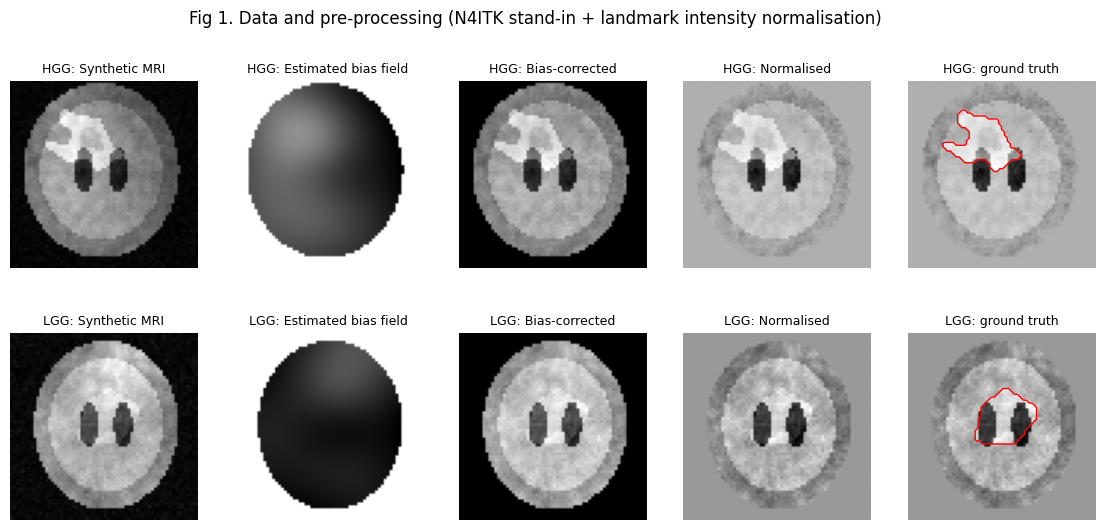

  saved figures/fig1_preprocessing.png
[3/7] extracting patches
      train patches (27867, 11, 11), val patches (9580, 11, 11), tumour fraction 0.25
[4/7] cuckoo-search dimensionality reduction
      kept 74/121 patch positions in 14.3s, best fitness 0.256


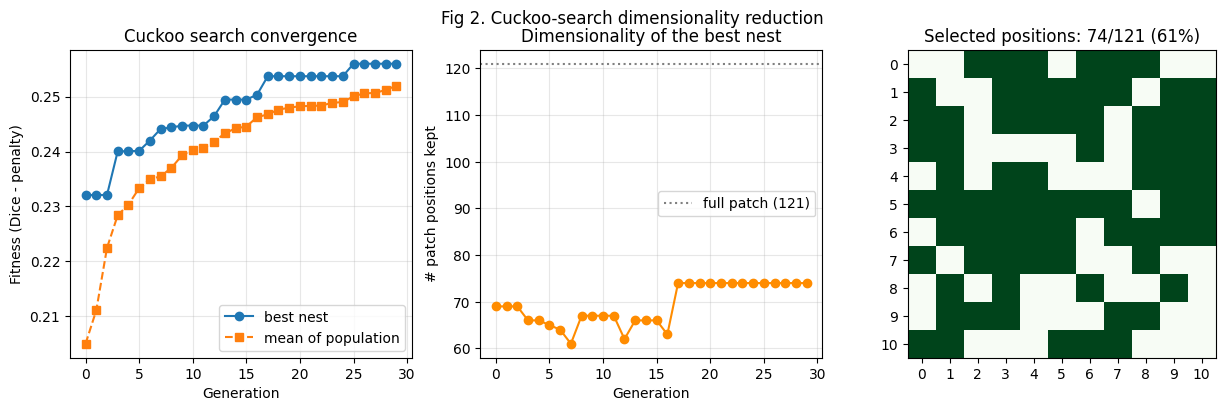

  saved figures/fig2_cuckoo_search.png
[5/7] training CNN baseline + ensemble of 4 CNNs
      CNN        val acc 0.921  (34s)
      ECNN-1     val acc 0.918  (20s)
      ECNN-2     val acc 0.917  (30s)
      ECNN-3     val acc 0.925  (35s)
      ECNN-4     val acc 0.922  (39s)


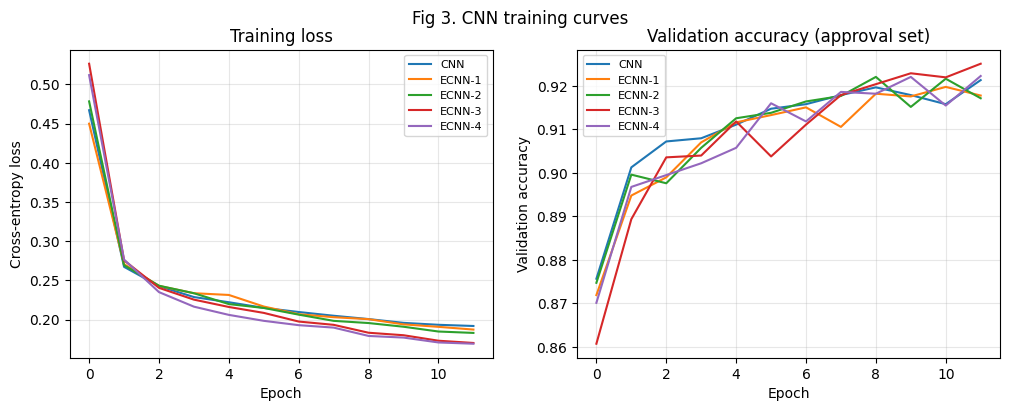

  saved figures/fig3_training_curves.png


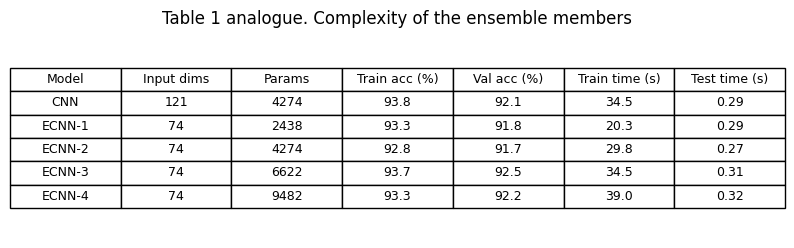

  saved figures/fig9_time_complexity.png
[6/7] training Random Forest baseline


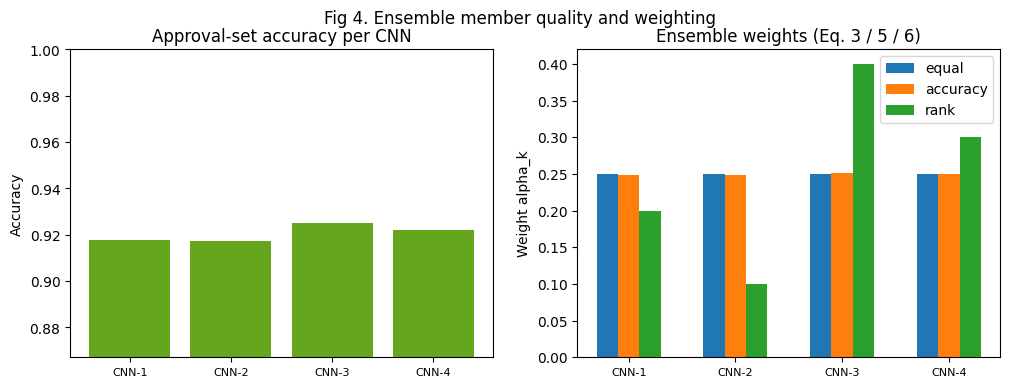

  saved figures/fig4_ensemble_weights.png
[7/7] evaluating on the test slices

Test results (mean over slices)
Method        Grade         DSC    PPV   Sens
Random Forest HGG         0.912  0.913  0.920
Random Forest LGG         0.736  0.737  0.795
Random Forest Combined    0.824  0.825  0.857
CNN           HGG         0.853  0.806  0.924
CNN           LGG         0.683  0.674  0.759
CNN           Combined    0.768  0.740  0.841
CNN + CS      HGG         0.821  0.787  0.881
CNN + CS      LGG         0.656  0.646  0.729
CNN + CS      Combined    0.739  0.716  0.805
ECNN          HGG         0.885  0.862  0.924
ECNN          LGG         0.701  0.725  0.738
ECNN          Combined    0.793  0.794  0.831


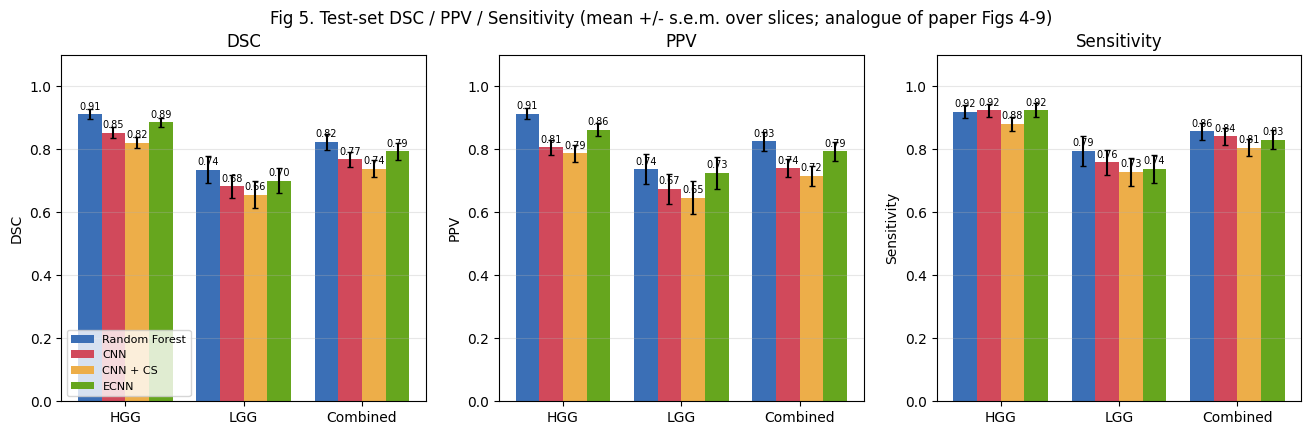

  saved figures/fig5_metrics_comparison.png


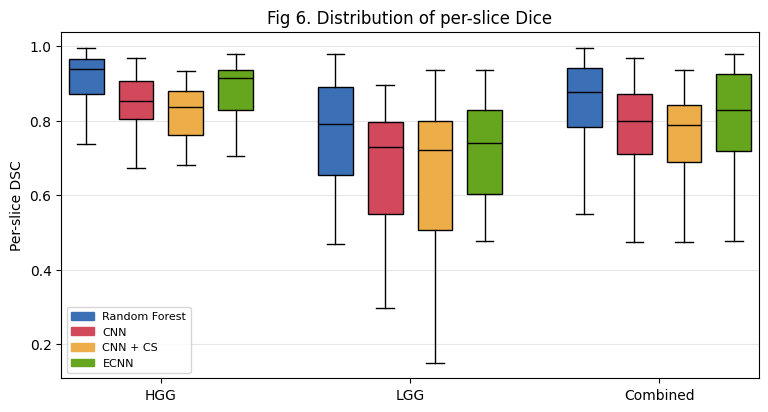

  saved figures/fig6_dice_boxplot.png


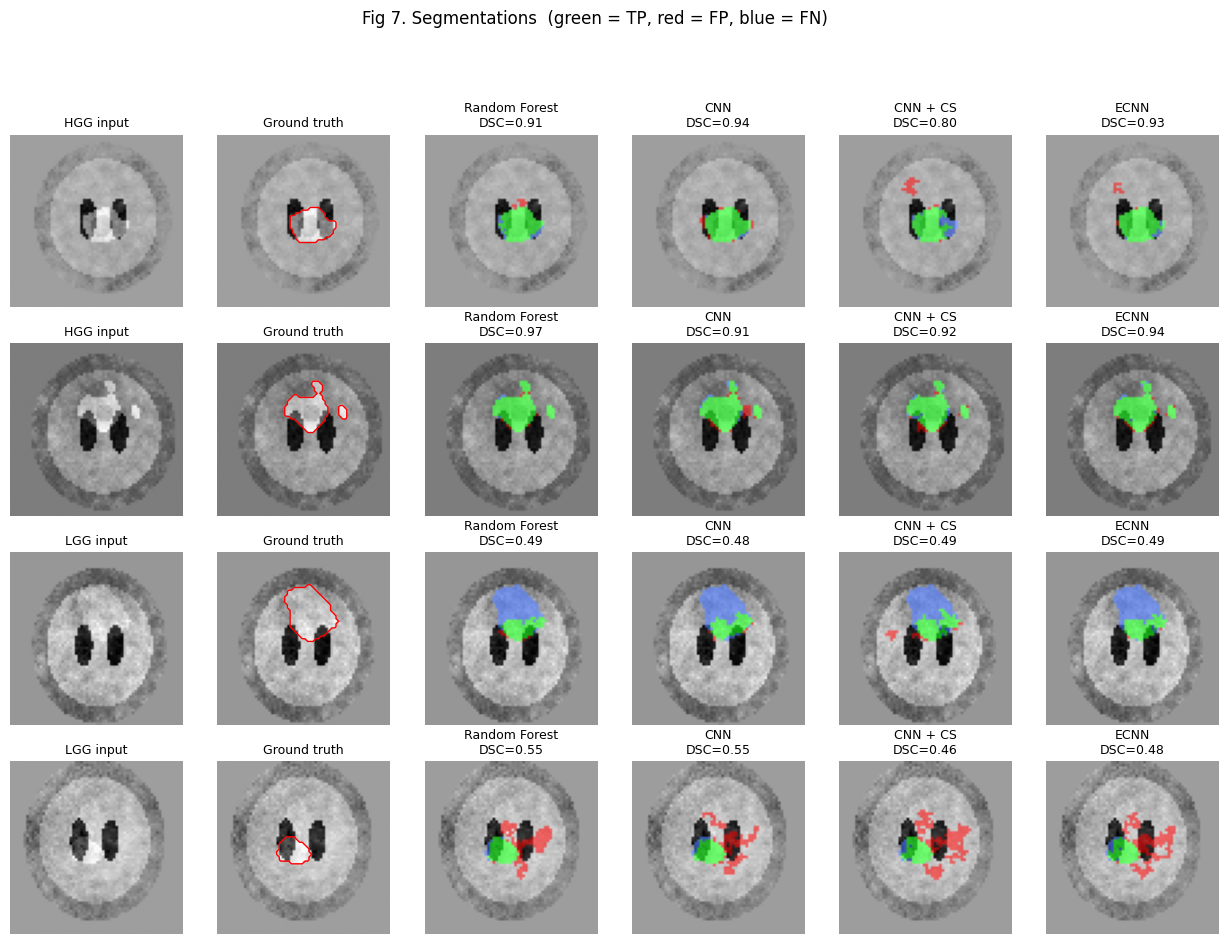

  saved figures/fig7_segmentation_examples.png


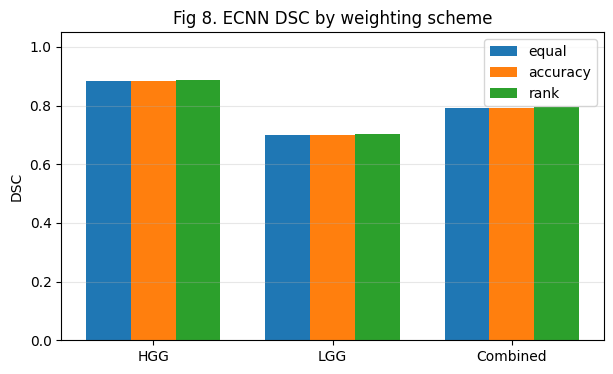

  saved figures/fig8_weighting_schemes.png

Done. Figures and results.csv are in: figures


In [2]:
main()